In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from numpy import linalg as LA
#https://becominghuman.ai/neural-networks-for-solving-differential-equations-fa230ac5e04c
#https://towardsdatascience.com/neural-odes-breakdown-of-another-deep-learning-breakthrough-3e78c7213795

In [ ]:
entrar = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] )
test = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95])

In [ ]:
# Função de Ativação Sigmóide
def sigmoid(z):
    return 1.0/(1.0+np.exp(-z))

# Função para retornar as derivadas da função Sigmóide
def sigmoid_prime(z):
    return sigmoid(z)*(1-sigmoid(z))

def sigmoid_secun(z):
    return sigmoid_prime(z)*sigmoid(z)*(-1.0+np.exp(-z))

In [ ]:
class Network(object):

    def __init__(self, sizes):
        """
        A lista 'sizes' contém o número de neurônios nas
        respectivas camadas da rede, [2, 3, 1]
        Os bias e pesos para a rede são inicializados aleatoriamente,
        usando uma distribuição Gaussiana com média 0 e variância 1.
        """

        self.num_layers = len(sizes)
        self.sizes = sizes
        self.biases = [np.random.randn(y, 1) for y in sizes[1:]]
        self.weights = [np.random.randn(y, x) for x, y in zip(sizes[:-1], sizes[1:])]
        self.biases[-1] = np.array([0])


    def feedforward(self, x):

        saidas_rede = []

        for i in x:
            # Lista para armazenar todas as ativações, camada por camada
            activations = [x]
            # Lista para armazenar todos os vetores z, camada por camada
            zs = []
            camada = 0
            i = np.array([i])
            entrada = [i]

            for b, w in zip(self.biases, self.weights):

                if camada == 0:
                    z = np.dot(w, entrada)+b
                    zs.append(z)
                    entrada = sigmoid(z)
                    activations.append(entrada)


                elif camada == 1:
                    z = np.dot(w, entrada)
                    zs.append(z)
                    activations.append(z)
                    saidas_rede.append(z)
                camada +=1
        return saidas_rede, zs, activations

    def leven_marquardt(self, training_data, eta):
        print(self.biases)
        print('coe')
        print(self.weights)
        print('------------------------------------------------------')
        j = 0
        e = 0
        while e < 2:
            j+=1
            j_v  = []
            j_w  = []
            j_b  = []
            erro = []
            for x in training_data:

                delta_b, delta_w, y = self.backprop(x)
                #print(delta_w[-2].T[0])

                j_v.append(delta_w[-1][0])
                j_w.append(delta_w[-2].T[0])
                j_b.append(delta_b[-2].T[0])
                erro.append(y[0][0]**2)
            j_v = np.array(j_v)
            j_w = np.array(j_w)
            j_b = np.array(j_b)
            erro = np.array(erro)


            print('------------------------------------')
            #print(np.dot(np.dot(np.linalg.inv(np.dot(j_v.T,j_v) + eta), j_v.T), erro))

            self.biases[0] = self.biases[0] - np.dot(np.dot(np.linalg.inv(np.dot(j_b.T,j_b) +
            np.identity(len(np.dot(j_b.T,j_b)))*eta), j_b.T), erro).reshape(self.biases[0].shape)

            self.weights[0] = self.weights[0] - np.dot(np.dot(np.linalg.inv(np.dot(j_w.T,j_w) +
            np.identity(len(np.dot(j_w.T,j_w)))*eta), j_w.T), erro).reshape(self.weights[0].shape)

            self.weights[-1][0] = self.weights[-1][0] - np.dot(np.dot(np.linalg.inv(np.dot(j_v.T,j_v) +
            np.identity(len(np.dot(j_v.T,j_v)))*eta), j_v.T), erro)
            e=0
            for i in erro:
                if i < 10**(-6):
                    e+=1
                #if erro[erro.argmin()] > 5*10**(-4)

            print("Epoch {} : {}".format(j, erro));




    def SGD(self, training_data, eta):

        print(self.biases)
        print('          ')
        print(self.weights)
        print('------------------------------------------------------')

        j = 0
        e=0
        while (e < 4):
            j+=1
            random.shuffle(training_data)
            e = 0
            for x in training_data:

                n_b = [np.zeros(b.shape) for b in self.biases]
                n_w = [np.zeros(w.shape) for w in self.weights]


                delta_b, delta_w, y = self.backprop(x)


                n_b = [nb+dnb for nb, dnb in zip(n_b, delta_b)]
                n_w = [nw+dnw for nw, dnw in zip(n_w, delta_w)]

                #print(nabla_b)
                #print(nabla_w)
                #print('--------------------------')

                self.biases = [b-(eta)*nb for b, nb in zip(self.biases, n_b)]
                self.weights = [w-(eta)*nw for w, nw in zip(self.weights, n_w)]

                #print(x)
                #print(self.biases)
                #print('      ')
                #print(self.weights)
                #print('------------------------------------------------------')


                erro, e = self.evaluate(x, e)


                print("Epoch {} : {}".format(j, erro));


    def backprop(self, x):


        delta_b = [np.zeros(b.shape) for b in self.biases]
        delta_w = [np.zeros(w.shape) for w in self.weights]

        # Feedforward

        saidas, zs, activations = self.feedforward([x])

        # Backward pass
        #problema artigo   ---->   np.exp(-x/5)*np.cos(x) - x*activations[-1]/5
        #problema 1        ---->
        #  x**3 + 2*x + x*x*(1 + 3*x*x) / (1 + x + x**3) - (x + (1 + 3*x*x) / (1 + x + x**3))*(1 + x*activations[-1])
        #problema 2        ---->   (x - x*activations[-1])



        y = (activations[-1] + x*np.sum(self.weights[-1].T*self.weights[0]*sigmoid_prime(zs[0])) -
            (x**3 + 2*x + x*x*(1 + 3*x*x) / (1 + x + x**3) - (x + (1 + 3*x*x) / (1 + x + x**3))*(1 + x*activations[-1])))


        d_v = (2*y * (activations[1] + x*self.weights[-1].T*sigmoid_prime(zs[0]) +
              (x + (1 + 3*x*x) / (1 + x + x**3))*x*activations[1]))


        d_w = (2*y * (self.weights[-1].T*sigmoid_prime(zs[0])*x + (self.weights[-1].T*sigmoid_prime(zs[0]) +
               self.weights[-1].T*self.weights[0]*sigmoid_secun(zs[0])*x)*x +
               (x + (1 + 3*x*x) / (1 + x + x**3))* x*self.weights[-1].T*sigmoid_prime(zs[0])*x))


        d_u = (2*y * (self.weights[-1].T*sigmoid_prime(zs[0]) + x*self.weights[-1].T*self.weights[0]*sigmoid_secun(zs[0]) +
              (x + (1 + 3*x*x) / (1 + x + x**3))* x*self.weights[-1].T*sigmoid_prime(zs[0])))

        #print(y)
        #print(d_v)
        #print(d_w)
        #print(d_u)
        #print('-------------------')

        delta_w[-1] = d_v.T
        delta_w[-2] = d_w

        delta_b[-1] = [0]
        delta_b[-2] = d_u

        #print(nabla_w)
        #print(nabla_b)
        #print('-------------------')
        return(delta_b, delta_w, y)
    def evaluate(self, test_data, e):
        test_results = []
        #for x in test_data:
        x = test_data


        saidas, zs, activations = self.feedforward([x])
        #print(x)
        #print('coe')
        #print(activations[-1][0][0])

        #prolema 2     ----> x - x*zs[-1]

        test_result = (activations[-1] + x*np.sum(self.weights[-1].T*self.weights[0]*sigmoid_prime(zs[0])) -
        (x**3 + 2*x + x*x*(1 + 3*x*x) / (1 + x + x**3) - (x + (1 + 3*x*x) / (1 + x + x**3))*(1 + x*activations[-1])))**2

        #test_results.append(test_result[0][0])
        #print(test_result)
        if test_result < 10**(-6):
        #return test_results[np.argmax(test_results)]
            e +=1
        return (test_result[0][0], e)
        #else:
        #   return (test_result[0][0], e)

In [ ]:
n = Network([1,10,1])

In [ ]:
#problema 1 ----> 0.005  embaralhar entrada
#problema 2  ---> 0.025

n.SGD(entrar,0.025)

[array([[ 0.6008754 ],
       [ 0.03049515],
       [ 1.98441116],
       [-0.05765415],
       [ 0.25724064],
       [-0.35897742],
       [-0.69982006],
       [ 1.74005259],
       [-0.01027071],
       [-0.21926024]]), array([0])]
          
[array([[-0.25561985],
       [ 1.91402378],
       [ 0.52702287],
       [-1.15726989],
       [ 0.2367449 ],
       [-0.47342508],
       [-0.13889464],
       [ 0.26351118],
       [-0.68503806],
       [ 1.11073816]]), array([[ 1.59066063, -1.41744941,  0.01670304,  1.11975135, -0.39529576,
        -0.27311547,  0.94370297,  1.22866632, -1.48324633,  0.80912431]])]
------------------------------------------------------
Epoch 1 : 0.3487149791527247
Epoch 1 : 0.1488880101463875
Epoch 1 : 5.001623957980467
Epoch 1 : 0.0035962933170608337
Epoch 1 : 0.9464547206374497
Epoch 1 : 0.07037781353917051
Epoch 1 : 1.9247431154203487
Epoch 1 : 0.16287461021511604
Epoch 1 : 0.20430381459595445
Epoch 1 : 1.7580361096123176
Epoch 2 : 0.6470768319967621
Epo

Epoch 50 : 0.0011578623896061813
Epoch 50 : 5.565381609940679e-06
Epoch 50 : 0.0011431827705218113
Epoch 50 : 4.650228593325501e-05
Epoch 50 : 0.002634892458055648
Epoch 50 : 0.0001681102330819067
Epoch 51 : 0.00271886789873915
Epoch 51 : 3.3314067903192766e-06
Epoch 51 : 0.003086603228718271
Epoch 51 : 8.365162850998027e-05
Epoch 51 : 0.002714355286078464
Epoch 51 : 3.053753196562489e-05
Epoch 51 : 5.814413758112873e-05
Epoch 51 : 4.9879415123464786e-05
Epoch 51 : 0.038590855530293566
Epoch 51 : 0.0035328509727874475
Epoch 52 : 0.002280389430307848
Epoch 52 : 0.00026580944171566577
Epoch 52 : 0.00094031321094683
Epoch 52 : 0.0003929747468555176
Epoch 52 : 0.001162066411120354
Epoch 52 : 2.5682668989156604e-06
Epoch 52 : 8.257265864276015e-05
Epoch 52 : 2.7935485345080575e-05
Epoch 52 : 0.003145174740721168
Epoch 52 : 0.017507232409968817
Epoch 53 : 0.02094340005356787
Epoch 53 : 0.005602336838115776
Epoch 53 : 0.04883586750673129
Epoch 53 : 0.0018781862280055422
Epoch 53 : 0.003548593

Epoch 96 : 7.093654547124536e-07
Epoch 96 : 0.001969885787485773
Epoch 96 : 1.7403840466651136e-05
Epoch 96 : 4.007990213168966e-05
Epoch 96 : 0.00010677486070174057
Epoch 96 : 0.003682893416722726
Epoch 97 : 2.600953086192763e-05
Epoch 97 : 0.00020486627585700938
Epoch 97 : 0.0009100506150490396
Epoch 97 : 0.001998260240902052
Epoch 97 : 0.00027023593478018627
Epoch 97 : 0.034899527434350465
Epoch 97 : 0.0046213966199255595
Epoch 97 : 6.5047014307686215e-06
Epoch 97 : 0.003926469183821242
Epoch 97 : 0.00046298736338732207
Epoch 98 : 0.0003572314363422179
Epoch 98 : 0.0003237653107815518
Epoch 98 : 8.635455724756981e-06
Epoch 98 : 3.0141911484838905e-05
Epoch 98 : 0.03217385879133791
Epoch 98 : 0.030659165507280015
Epoch 98 : 0.0002537500733137194
Epoch 98 : 0.002899112553298111
Epoch 98 : 0.001279184590646509
Epoch 98 : 1.1826393640205081e-06
Epoch 99 : 0.0020478797222745655
Epoch 99 : 0.00024480340710291733
Epoch 99 : 0.0003889508950840357
Epoch 99 : 0.0008653137473266645
Epoch 99 : 

Epoch 139 : 0.0011429819649546597
Epoch 139 : 1.5464026738169367e-07
Epoch 139 : 0.030520629113112686
Epoch 139 : 0.0016209357283676045
Epoch 139 : 0.00013081534115872657
Epoch 139 : 1.4699055654744586e-05
Epoch 139 : 0.0005281058763955592
Epoch 140 : 0.00037516426037367915
Epoch 140 : 0.002441400637788853
Epoch 140 : 0.0006706767210510578
Epoch 140 : 8.840395035308791e-06
Epoch 140 : 0.00047124418175622927
Epoch 140 : 4.055206225893948e-06
Epoch 140 : 5.278981204944842e-05
Epoch 140 : 0.00015698877096119343
Epoch 140 : 0.002191960345544969
Epoch 140 : 9.213234796595059e-05
Epoch 141 : 5.108215512237721e-06
Epoch 141 : 0.002562888645954493
Epoch 141 : 0.0003029760884246117
Epoch 141 : 0.0029246941151994206
Epoch 141 : 0.0007954095268637982
Epoch 141 : 0.0010983520919999174
Epoch 141 : 7.0774646665370984e-06
Epoch 141 : 5.417882055957667e-08
Epoch 141 : 0.002430231006533907
Epoch 141 : 2.0022193307101826e-06
Epoch 142 : 0.0024643777752026384
Epoch 142 : 0.00020843830522132315
Epoch 142 

Epoch 186 : 1.463312591712496e-06
Epoch 186 : 0.0009516203668046404
Epoch 186 : 3.364638052564206e-06
Epoch 186 : 2.888468505669082e-06
Epoch 186 : 0.0021771598551508465
Epoch 186 : 7.374911226353201e-06
Epoch 186 : 0.00871186976892703
Epoch 187 : 0.0012865115624754002
Epoch 187 : 0.0009358510187115583
Epoch 187 : 0.0024853144044962527
Epoch 187 : 0.0006357152038762318
Epoch 187 : 0.0020188999412846472
Epoch 187 : 3.2410489349120534e-05
Epoch 187 : 1.267586251076156e-05
Epoch 187 : 4.916965309685246e-05
Epoch 187 : 8.016416703505661e-06
Epoch 187 : 0.0008761121680445347
Epoch 188 : 0.0002879640470650087
Epoch 188 : 0.0005803948926048026
Epoch 188 : 0.0008452854717061158
Epoch 188 : 0.0003158207149803167
Epoch 188 : 0.020635622744543183
Epoch 188 : 0.005149470126407698
Epoch 188 : 0.004321301316864786
Epoch 188 : 3.6968798361597604e-08
Epoch 188 : 1.4777826756775611e-06
Epoch 188 : 9.183697963430337e-05
Epoch 189 : 0.0012202232639318773
Epoch 189 : 1.2026050953650714e-05
Epoch 189 : 5.5

...

Epoch 2680 : 0.000124386403521965
Epoch 2680 : 0.0011203964431159177
Epoch 2680 : 1.1158029610917112e-06
Epoch 2680 : 0.0005905953336751756
Epoch 2680 : 0.00026008115239714965
Epoch 2681 : 5.6483273261058286e-05
Epoch 2681 : 6.359216666893364e-07
Epoch 2681 : 0.006143899797481702
Epoch 2681 : 0.00028555313781035435
Epoch 2681 : 0.00023825045231419436
Epoch 2681 : 0.0036700934766499393
Epoch 2681 : 0.0011712855807386876
Epoch 2681 : 0.0006951733059730734
Epoch 2681 : 8.28450169262468e-05
Epoch 2681 : 0.0012210414050909761
Epoch 2682 : 0.00015108018163481962
Epoch 2682 : 0.0003494101430879054
Epoch 2682 : 0.00011561608725906885
Epoch 2682 : 1.0968620472714489e-07
Epoch 2682 : 0.000971994028459519
Epoch 2682 : 1.3058286936253876e-06
Epoch 2682 : 0.002167180399767417
Epoch 2682 : 1.2537245566522966e-07
Epoch 2682 : 0.006107853016521322
Epoch 2682 : 4.253258579666983e-05
Epoch 2683 : 0.009028641115812044
Epoch 2683 : 0.0019711554273726985
Epoch 2683 : 0.0015480785374257717
Epoch 2683 : 0.00

Epoch 2722 : 5.7252108176475215e-06
Epoch 2722 : 0.00012532513757901738
Epoch 2723 : 1.0693962322694454e-06
Epoch 2723 : 0.0006926797522211056
Epoch 2723 : 0.0015497520222487223
Epoch 2723 : 0.0025364688084156817
Epoch 2723 : 0.0010705750799495611
Epoch 2723 : 0.0015215278600658375
Epoch 2723 : 1.651845897789685e-05
Epoch 2723 : 1.16673405606672e-07
Epoch 2723 : 6.231600608109189e-05
Epoch 2723 : 0.0007599763738283128
Epoch 2724 : 0.001077617967851696
Epoch 2724 : 0.0010084229228971295
Epoch 2724 : 0.016071066109646086
Epoch 2724 : 0.0001910437709722347
Epoch 2724 : 2.579078156087195e-05
Epoch 2724 : 0.0007818309090996513
Epoch 2724 : 0.0007300316591184084
Epoch 2724 : 2.397443558699972e-05
Epoch 2724 : 3.7962422156590135e-05
Epoch 2724 : 3.678555311461729e-05
Epoch 2725 : 0.0013685411096436059
Epoch 2725 : 0.0001388345926250202
Epoch 2725 : 0.0003287755072092844
Epoch 2725 : 2.912069690062192e-07
Epoch 2725 : 0.00010691845576090998
Epoch 2725 : 3.951246118093991e-06
Epoch 2725 : 4.233

Epoch 2760 : 0.0039594556177149276
Epoch 2760 : 0.0002110768741078153
Epoch 2760 : 0.0025492460759721485
Epoch 2761 : 1.3459559920469692e-06
Epoch 2761 : 0.0013291369874094373
Epoch 2761 : 0.00017010256122417859
Epoch 2761 : 0.00034922346274558194
Epoch 2761 : 0.00019986396820554443
Epoch 2761 : 0.0003916453681125797
Epoch 2761 : 0.00042646139654222846
Epoch 2761 : 0.0012551944573591604
Epoch 2761 : 0.0009203141439160779
Epoch 2761 : 9.639646656755573e-07
Epoch 2762 : 5.0370135686902415e-08
Epoch 2762 : 0.00045583670288639497
Epoch 2762 : 2.208099053718489e-06
Epoch 2762 : 0.0012059954962311368
Epoch 2762 : 0.00010386107268197378
Epoch 2762 : 0.00033700982081032643
Epoch 2762 : 7.035129031371804e-05
Epoch 2762 : 0.007389139287470561
Epoch 2762 : 0.004295097128875735
Epoch 2762 : 6.969905382351784e-05
Epoch 2763 : 0.002222817319936491
Epoch 2763 : 0.0003477536023257932
Epoch 2763 : 0.00046012840524233955
Epoch 2763 : 9.366590337836715e-05
Epoch 2763 : 1.738792726089784e-05
Epoch 2763 : 

Epoch 2802 : 0.0005231029962592419
Epoch 2802 : 0.001605667977883382
Epoch 2802 : 1.7001551825653524e-06
Epoch 2802 : 1.3560276240477006e-07
Epoch 2803 : 0.0003339370631262265
Epoch 2803 : 2.9763404156506187e-06
Epoch 2803 : 2.2571623615038918e-06
Epoch 2803 : 5.181188574055886e-06
Epoch 2803 : 6.984479006876883e-07
Epoch 2803 : 0.0027362166316469653
Epoch 2803 : 1.8832861324331342e-05
Epoch 2803 : 0.002717712079356818
Epoch 2803 : 0.0005405687982382528
Epoch 2803 : 1.9563978401631295e-05
Epoch 2804 : 0.0008969636823648956
Epoch 2804 : 0.0012771197415136517
Epoch 2804 : 0.0009524645032895551
Epoch 2804 : 2.5564991597982972e-05
Epoch 2804 : 0.003675841832693793
Epoch 2804 : 5.953663904127916e-07
Epoch 2804 : 0.00013364065901673777
Epoch 2804 : 5.956312131687008e-06
Epoch 2804 : 0.0015432143446486545
Epoch 2804 : 0.00031626860974203857
Epoch 2805 : 0.0002342154620131893
Epoch 2805 : 0.00028081561138083427
Epoch 2805 : 0.00013295439893323162
Epoch 2805 : 0.002242388399201131
Epoch 2805 : 

Epoch 2842 : 0.00047304091394304867
Epoch 2842 : 8.302543677399196e-09
Epoch 2842 : 0.00013858000140711912
Epoch 2842 : 4.591128501390442e-06
Epoch 2842 : 0.0022885720899220767
Epoch 2842 : 7.392266730114479e-06
Epoch 2843 : 1.3544746800663203e-06
Epoch 2843 : 0.0004404920810320096
Epoch 2843 : 1.0989640885306048e-05
Epoch 2843 : 9.024500934649604e-05
Epoch 2843 : 0.0015438478650829958
Epoch 2843 : 0.0014538564538842354
Epoch 2843 : 0.0002485012588757186
Epoch 2843 : 3.551920211443528e-05
Epoch 2843 : 0.00017619075824386863
Epoch 2843 : 8.756140033045795e-08
Epoch 2844 : 2.06462599756798e-06
Epoch 2844 : 0.0014641869211890533
Epoch 2844 : 4.449288168757253e-07
Epoch 2844 : 9.433050317565415e-05
Epoch 2844 : 0.000750046879207734
Epoch 2844 : 0.00028307423475806934
Epoch 2844 : 0.0006392480501311928
Epoch 2844 : 0.0004155379951035012
Epoch 2844 : 0.0001570741132042806
Epoch 2844 : 0.0037391013446666115
Epoch 2845 : 0.0011800327766725233
Epoch 2845 : 0.002468265631596997
Epoch 2845 : 6.79

In [ ]:
#l = Network([1,10,1])

In [ ]:
#l.leven_marquardt(entrar, 0.25)

In [ ]:
result, zs, activations = n.feedforward(test)
#result2, zs, activations = l.feedforward(test)

In [ ]:
#result

In [ ]:
sa = []
for i,j in zip(result,test):
    sa.append((1 + j*i[0][0]))
sa
#sb = []
#for i,j in zip(result2,test):
#    sb.append((2 + j*i[0][0]))
#sb

[0.9547661758258632,
 0.8787609750181273,
 0.8234942688813784,
 0.7906417878315476,
 0.7817025105398572,
 0.797905630175042,
 0.8401395918965319,
 0.9089071692016143,
 1.0043070607330087,
 1.126039826692427]

In [ ]:
#problema 2       ---->  test + 1 + np.exp(-test)
#problema 1       ---->  np.exp(-test*test/2)/ (1 + test + test**3) + test*test
#problema artigo  ---->  np.exp(-test/5)*np.sin(test)
analitica = np.exp(-test*test/2)/ (1 + test + test**3) + test*test
analitica

array([0.953578  , 0.87982138, 0.82831391, 0.79778534, 0.78889441,
       0.80334204, 0.84313864, 0.91005205, 1.0052798 , 1.12934238])

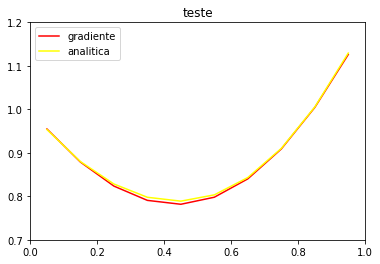

In [ ]:
plt.plot(test, sa, color='red', label='gradiente')
#plt.plot(test, sb, color='blue', label='leven_marquardt')
plt.plot(test, analitica, color='yellow', label='analitica')
plt.title("teste")
plt.legend()
plt.axis([0, 1, 0.7, 1.2])
plt.show()

In [ ]:
#plt.semilogy(test, abs(analitica - sa))
#plt.show()

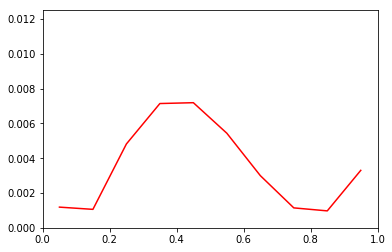

In [ ]:
plt.plot(test, abs(analitica - sa), color='red', label='gradiente')
#plt.plot(test, abs(analitica - sb), color='blue', label='leven_marquardt')
plt.axis([0, 1, 0, 0.0125])

plt.show()